In [1]:
import matplotlib.pyplot as plt
import h5py
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from datetime import datetime
import os as os 
import numpy as np
import cmocean
import netCDF4 as nc
from cartopy.feature import LAND
from cartopy.feature import ShapelyFeature
import xarray as xr
import geopandas as gpd
import os as os 
import scipy
import cfgrib
# import fonctions as funcs

#For TOEddies
import sys
sys.path.insert(1, '\\TOEeddies\\TOEddies_WHIRLS')
import pyTOEddies_functions as f
# import plot_toe_eddies as plot
import class_EDDIES as ed
import pandas as pd
from pathlib import Path
from datetime import datetime, timedelta
from tools import *

In [2]:
def load_satellite(adt_path):

    # ds = xr.open_dataset(adt_daily_dir + file_adt)
    ds = xr.open_dataset(adt_path)
    if "time" in ds:
        ds = ds.drop_vars("time")
    ds.close()
    return {
        "dataset": ds,
        "lon": ds.longitude,
        "lat": ds.latitude,
        "adt": ds.adt,
        "ugos": np.squeeze(ds.ugos),
        "vgos": np.squeeze(ds.vgos)
    }
from pathlib import Path
from datetime import datetime

def get_closest_sst_file(date, sst_dir):
    """
    Return the SST file corresponding to `date`, or the closest available date.

    Parameters
    ----------
    date : str
        Date in the format "YYYY-MM-DD".
    sst_dir : str or Path
        Directory containing the SST files.

    Returns
    -------
    str
        Full path to the selected SST file.
    """

    sst_dir = Path(sst_dir)

    target_date = datetime.strptime(date, "%Y-%m-%d")

    # Exact filename
    exact_file = sst_dir / f"BT_masked_Meteosat_{target_date.strftime('%Y%m%d')}.nc"
    print(exact_file)
    if exact_file.exists():
        return str(exact_file)

    # Search all SST files
    files = sorted(sst_dir.glob("BT_masked_Meteosat_*.nc"))

    if len(files) == 0:
        raise FileNotFoundError(f"No SST files found in {sst_dir}")

    available_dates = []
    for f in files:
        try:
            date_str = f.stem.split("_")[-1]   # e.g. 20260710
            file_date = datetime.strptime(date_str, "%Y%m%d")
            available_dates.append((file_date, f))
        except ValueError:
            continue

    if len(available_dates) == 0:
        raise FileNotFoundError("No valid SST files found.")

    # Find the closest date
    closest_date, closest_file = min(
        available_dates,
        key=lambda x: abs((x[0] - target_date).days)
    )

    print(f"No SST file for {date}. Using {closest_date.strftime('%Y-%m-%d')} instead.")

    return str(closest_file)

def load_satellite(adt_path):

    # ds = xr.open_dataset(adt_daily_dir + file_adt)
    ds = xr.open_dataset(adt_path)
    if "time" in ds:
        ds = ds.drop_vars("time")
    ds.close()
    return {
        "dataset": ds,
        "lon": ds.longitude,
        "lat": ds.latitude,
        "adt": ds.adt,
        "ugos": np.squeeze(ds.ugos),
        "vgos": np.squeeze(ds.vgos)
    }
from pathlib import Path
from datetime import datetime

def get_closest_adt_file(date, sst_dir):
    """
    Return the SST file corresponding to `date`, or the closest available date.

    Parameters
    ----------
    date : str
        Date in the format "YYYY-MM-DD".
    sst_dir : str or Path
        Directory containing the SST files.

    Returns
    -------
    str
        Full path to the selected SST file.
    """

    sst_dir = Path(sst_dir)

    target_date = datetime.strptime(date, "%Y-%m-%d")

    # Exact filename
    exact_file = sst_dir / f"tr.nc"
    print(exact_file)
    if exact_file.exists():
        return str(exact_file)

    # Search all SST files
    files = sorted(sst_dir.glob("BT_masked_Meteosat_*.nc"))

    if len(files) == 0:
        raise FileNotFoundError(f"No SST files found in {sst_dir}")

    available_dates = []
    for f in files:
        try:
            date_str = f.stem.split("_")[-1]   # e.g. 20260710
            file_date = datetime.strptime(date_str, "%Y%m%d")
            available_dates.append((file_date, f))
        except ValueError:
            continue

    if len(available_dates) == 0:
        raise FileNotFoundError("No valid SST files found.")

    # Find the closest date
    closest_date, closest_file = min(
        available_dates,
        key=lambda x: abs((x[0] - target_date).days)
    )

    print(f"No SST file for {date}. Using {closest_date.strftime('%Y-%m-%d')} instead.")

    return str(closest_file)

In [27]:
##### POSITION VARIABLES #####
ft=10
small_box = False

lon_min, lon_max, lat_min, lat_max = 9, 20, -39.5, -33
pos_west,pos_east,pos_south,pos_north  = 9, 20, -39.5,-33  #Reset the area
vmin_adt = -0.25
vmax_adt = 1.55
# proj = ccrs.Mercator(central_longitude=(pos_south + pos_north)//2,min_latitude=pos_south+3,max_latitude=pos_north+3)
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent

In [38]:
date = "2026-07-15"
yr = date[0:4]
mnth = date[5:7]
day = date[-2:]
dir_data = "/Volumes/science/MD252_WHIRLS/REP/data/"
dir_figures = "/Volumes/science/MD252_WHIRLS/REP/figures/"

dir_adcp = dir_data + "SADCP/WHIRLS_NB150_TOT_osite.nc"

sst_path = dir_data + f"/SST/"
dir_eddies = dir_data + f"Eddies/"
save_fig = dir_figures + f"AVISO/"

adt_daily_dir = dir_data + "daily_adt/"

fname_bathy = dir_data + "bathymetry/etopo2.nc"

In [39]:
path_nav = "/Volumes/science/MD252_WHIRLS/NAV/"
files = np.asarray(sorted(os.listdir(path_nav)))
date_str = date.replace("-", "")
idx = np.where(np.char.startswith(files, date_str))[0]
files_nav = files[:idx[0]+1]
lat_list = []
lon_list = []

for file in files_nav:
    ds = xr.open_dataset(path_nav + file)
    lat_list.append(ds["lat"].values)
    lon_list.append(ds["long"].values)   # or "long" if that's the actual variable name

if len(lat_list) > 1:
    lats_bato = np.concatenate(lat_list)
    longs_bato = np.concatenate(lon_list)
else:
    lats_bato = lat_list
    longs_bato = lon_list
ship_center = (longs_bato[-1], lats_bato[-1])
ship_x, ship_y = ship_center

In [40]:
adcp_data = xr.open_dataset(dir_adcp)
uvel_adcp = adcp_data.UVEL_ADCP
vvel_adcp = adcp_data.VVEL_ADCP
lon_adcp = adcp_data.LONGITUDE
lat_adcp = adcp_data.LATITUDE
depth_adcp = adcp_data.DEPH

ref_dat = adcp_data.REFERENCE_DATE_TIME
import numpy as np

ref = np.datetime64('1950-01-01T00:00:00')
t_adcp = adcp_data.JULD_ADCP
t_adcp = ref + (t_adcp * 86400).astype('timedelta64[s]')
adcp_data['time'] = t_adcp 

new_adcp = xr.Dataset(
    data_vars={
        "uvel_adcp": (("time", "depth"), uvel_adcp.values),
        "vvel_adcp": (("time", "depth"), vvel_adcp.values),
        "lon_adcp": (("time"), lon_adcp.values),
        "lat_adcp": (("time"), lat_adcp.values),
    },
    coords={
        "time": t_adcp.values,
        "depth": depth_adcp.values,
    },
)
new_adcp = get_time_mask(mnth, day, new_adcp, new_adcp.time, dm=True)

x_dist = along_track_distance(
        new_adcp.lon_adcp.values,
        new_adcp.lat_adcp.values
    )


/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_60205/3651056139.py:13: UserWarning: Converting non-nanosecond precision timedelta values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  t_adcp = ref + (t_adcp * 86400).astype('timedelta64[s]')


In [41]:
##### BATHYMETRY #####
bathymetry_data = xr.open_dataset(fname_bathy)
land_feature = cfeature.NaturalEarthFeature(
    category='physical',
    name='land',
    scale='10m',
    edgecolor='black',
    facecolor='gray'
)

# Extract relevant variables (e.g., longitude, latitude, depth)
lon = bathymetry_data['lon']
lat = bathymetry_data['lat']
depth = bathymetry_data['topo']
LON = bathymetry_data['lon']
LAT = bathymetry_data['lat']
depth = bathymetry_data['topo']
lon_subset = LON.sel(lon=slice(lon_min, lon_max))
lat_subset = LAT.sel(lat=slice(lat_min, lat_max))
depth_subset = depth.sel(lon=slice(lon_min, lon_max), lat=slice(lat_min, lat_max))


In [42]:
daily_adt_files = sorted(os.listdir(adt_daily_dir))
curr_adt_idx = np.where(np.char.startswith(daily_adt_files, date))[0]
sat = load_satellite(adt_daily_dir + daily_adt_files[curr_adt_idx[0]])


In [43]:
sst_file = get_closest_sst_file(date, sst_path)
sst_data = xr.open_dataset(sst_file)
lats_sst = sst_data['lat']
lons_sst = sst_data['lon']
sst = sst_data['BT_masked']
sst = np.where(sst==np.nan, 0, sst)

/Volumes/science/MD252_WHIRLS/REP/data/SST/BT_masked_Meteosat_20260715.nc
No SST file for 2026-07-15. Using 2026-07-14 instead.


In [44]:
dir_eddies_curr = dir_eddies + f"{date}"
anti, cyc = load_eddies(dir_eddies_curr)

In [45]:
sat['adt']

<xarray.DataArray 'adt' (time: 1, latitude: 156, longitude: 180)> Size: 225kB
[28080 values with dtype=float64]
Coordinates:
  * latitude   (latitude) float32 624B -44.44 -44.31 -44.19 ... -25.19 -25.06
  * longitude  (longitude) float32 720B 5.812 5.938 6.062 ... 27.94 28.06 28.19
Dimensions without coordinates: time
Attributes:
    comment:        The absolute dynamic topography is the sea surface height...
    grid_mapping:   crs
    long_name:      Absolute dynamic topography
    standard_name:  sea_surface_height_above_geoid
    units:          m

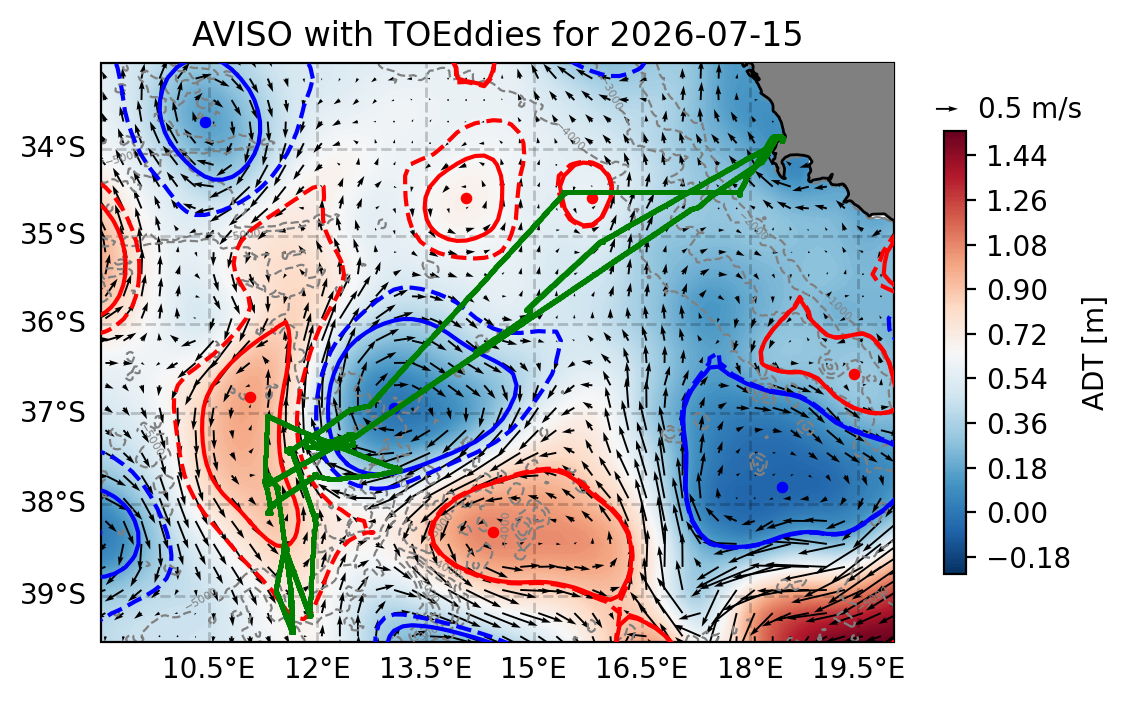

In [46]:
import matplotlib.lines as mlines
from matplotlib.patches import FancyArrowPatch
plot_adt_map(sat, anti, cyc, extent, f"AVISO with TOEddies for {date}", proj, crs, ft, vmin_adt, vmax_adt, lon_subset, lat_subset, depth_subset, longs_bato, lats_bato, new_adcp, x_dist)
plt.savefig(save_fig + f"ADT/{date}_adt.png")

In [47]:
lon = lons_sst
lat = lats_sst
print("lon finite:", np.isfinite(lon.values).all())
print("lat finite:", np.isfinite(lat.values).all())

print("NaNs in lon:", np.isnan(lon.values).sum())
print("NaNs in lat:", np.isnan(lat.values).sum())

print("Infs in lon:", np.isinf(lon.values).sum())
print("Infs in lat:", np.isinf(lat.values).sum())

lon finite: True
lat finite: True
NaNs in lon: 0
NaNs in lat: 0
Infs in lon: 0
Infs in lat: 0


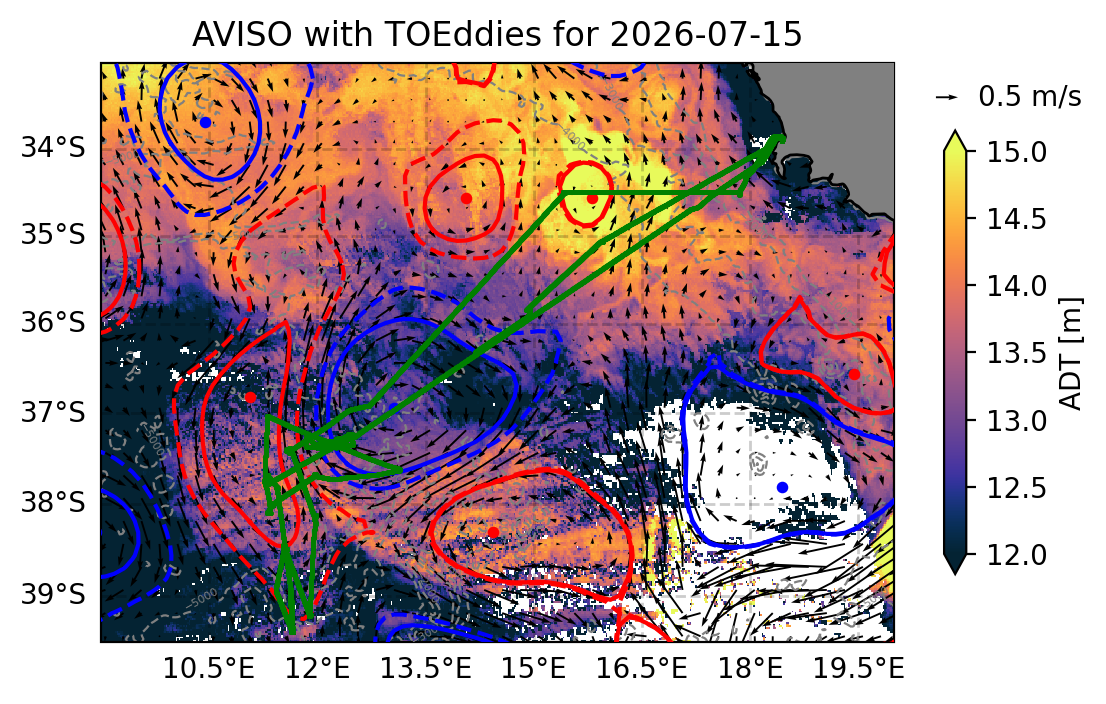

In [48]:
plot_sst_map(sat, lons_sst.values, lats_sst.values, sst, anti, cyc, extent, f"AVISO with TOEddies for {date}", proj, crs, ft, vmin_adt, vmax_adt, lon_subset, lat_subset, depth_subset, longs_bato, lats_bato, new_adcp, x_dist)
save_fig_sst = dir_figures + "SST/"
plt.savefig(save_fig_sst + f"{date}_sst.png")

In [23]:
print(lons_sst.shape, lats_sst.shape, sst.shape)
print(type(lons_sst), type(lats_sst), type(sst))
print(np.ma.isMaskedArray(lons_sst), np.ma.isMaskedArray(lats_sst), np.ma.isMaskedArray(sst))

(1000,) (550,) (550, 1000)
<class 'xarray.core.dataarray.DataArray'> <class 'xarray.core.dataarray.DataArray'> <class 'numpy.ndarray'>
False False False
